In [1]:
import os, json, time, math, random, copy
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, confusion_matrix)
import matplotlib.pyplot as plt


SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)


MODEL_NAME = "HooshvareLab/bert-fa-base-uncased"
MAX_LEN    = 128         
BATCH      = 128
EPOCHS = 2
EVAL_EVERY = 1000
USE_AMP = True
LR_ENCODER, LR_HEAD = 2e-5, 1e-3
WEIGHT_DECAY, WARMUP, CLIP = 0.01, 0.06, 1.0        
PATIENCE   = 3
LAMBDA_BAND = 1.0
FREEZE_ALL_BUT_LAST = False    


REC = ["recommended", "not_recommended", "no_idea"]
BAND = ["low", "medium", "high"]
BAND_CODE = {"low": 0, "medium": 1, "high": 2}
REC_ID = {c: i for i, c in enumerate(REC)}; BAND_ID = {c: i for i, c in enumerate(BAND)}


BASE_INPUT = Path("/kaggle/input")
DATA_DIR = BASE_INPUT / "train_sub" # Using this as the root just for print
OUT = Path("/kaggle/working"); OUT.mkdir(exist_ok=True)


dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Data root: {BASE_INPUT}")
print(f"Device: {dev}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("WARNING: GPU not detected! Please enable it in Kaggle settings.")

Data root: /kaggle/input
Device: cuda
GPU: Tesla T4


In [2]:
from pathlib import Path
import pandas as pd

all_csvs = list(Path("/kaggle/input").rglob("*.csv"))
file_map = {f.name: f for f in all_csvs}

print(f"Found files: {list(file_map.keys())}")

def load(name):
    if name not in file_map:
        raise FileNotFoundError(f"{name} not found!")
    return pd.read_csv(file_map[name], dtype=str, keep_default_na=False, na_values=[""])

train = load("train_sub.csv")
val   = load("val_sub.csv")
test  = load("test.csv")

print(f"\nLoaded successfully:")
print(f"Train: {len(train):,} rows")
print(f"Val:   {len(val):,} rows")
print(f"Test:  {len(test):,} rows")

Found files: ['pseudo_sub.csv', 'test.csv', 'train_sub.csv', 'val_sub.csv']

Loaded successfully:
Train: 354,599 rows
Val:   92,164 rows
Test:  917,785 rows


In [3]:
def load(name):
    if name not in file_map:
        raise FileNotFoundError(f"{name} not found")
    return pd.read_csv(file_map[name], dtype=str, keep_default_na=False, na_values=[""])

train = load("train_sub.csv")
val   = load("val_sub.csv")
test  = load("test.csv")
print(f"Loaded -> Train: {len(train):,} | Val: {len(val):,} | Test: {len(test):,}")


tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(df):
    ids = []
    texts = df["body"].tolist()
    for i in range(0, len(texts), 20_000):
        ids += tok(texts[i:i+20_000], truncation=True, max_length=MAX_LEN,
                   add_special_tokens=True)["input_ids"]
    y_rec  = df["recommendation_status"].map(REC_ID).fillna(-100).astype(int).values
    y_band = df["rating_band"].map(BAND_ID).fillna(-100).astype(int).values
    return ids, y_rec, y_band

class DS(Dataset):
    def __init__(self, df): self.ids, self.yr, self.yb = encode(df)
    def __len__(self): return len(self.ids)
    def __getitem__(self, i): return self.ids[i], self.yr[i], self.yb[i]

def collate(batch):
    L = max(len(b[0]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id, dtype=torch.long)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for k, (x, _, _) in enumerate(batch):
        ids[k, :len(x)] = torch.tensor(x); att[k, :len(x)] = 1
    return ids, att, torch.tensor([b[1] for b in batch]), torch.tensor([b[2] for b in batch])

t0 = time.time()
ds_tr, ds_va, ds_te = DS(train), DS(val), DS(test)
print(f"tokenized in {time.time()-t0:.0f}s")

lens = np.array([len(x) for x in ds_tr.ids[:50000]])
print("truncated share (train sample):", (lens >= MAX_LEN).mean().round(3))

g = torch.Generator(); g.manual_seed(SEED)
dl_tr = DataLoader(ds_tr, batch_size=BATCH, shuffle=True, collate_fn=collate, generator=g,
                   num_workers=2, pin_memory=True)

def eval_loader(ds, bs=256):
    order = np.argsort([len(x) for x in ds.ids])
    sub = torch.utils.data.Subset(ds, order)
    return DataLoader(sub, batch_size=bs, shuffle=False, collate_fn=collate, num_workers=2), order

dl_va, _ = eval_loader(ds_va)
dl_te, _ = eval_loader(ds_te)
print("DataLoaders ready!")

Loaded -> Train: 354,599 | Val: 92,164 | Test: 917,785


config.json:   0%|          | 0.00/440 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

tokenized in 63s
truncated share (train sample): 0.003
DataLoaders ready!


In [4]:
class TwoHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = AutoModel.from_pretrained(MODEL_NAME)
        h = self.enc.config.hidden_size
        self.drop = nn.Dropout(0.1)
        self.rec, self.band = nn.Linear(h, 3), nn.Linear(h, 3)
    def forward(self, ids, att):
        z = self.drop(self.enc(input_ids=ids, attention_mask=att).last_hidden_state[:, 0])
        return self.rec(z), self.band(z)

model = TwoHead().to(dev)
if FREEZE_ALL_BUT_LAST:
    for p in model.enc.parameters(): p.requires_grad = False
    for p in model.enc.encoder.layer[-1].parameters(): p.requires_grad = True

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"params total={n_total:,} trainable={n_train:,}")

def class_weights(y, k):
    cnt = np.bincount(y[y >= 0], minlength=k).astype(float)
    return torch.tensor(cnt.sum() / (k * cnt), dtype=torch.float32, device=dev)
W_REC, W_BAND = class_weights(ds_tr.yr, 3), class_weights(ds_tr.yb, 3)
print("class weights:", W_REC.tolist(), W_BAND.tolist())

def masked_ce(logits, y, w):
    ok = y != -100
    if not ok.any(): return logits.sum() * 0.0
    return F.cross_entropy(logits[ok], y[ok], weight=w)

no_decay = ("bias", "LayerNorm.weight")
groups = [
 {"params": [p for n, p in model.enc.named_parameters() if p.requires_grad and not any(x in n for x in no_decay)],
  "lr": LR_ENCODER, "weight_decay": WEIGHT_DECAY},
 {"params": [p for n, p in model.enc.named_parameters() if p.requires_grad and any(x in n for x in no_decay)],
  "lr": LR_ENCODER, "weight_decay": 0.0},
 {"params": list(model.rec.parameters()) + list(model.band.parameters()),
  "lr": LR_HEAD, "weight_decay": 0.0},
]
opt = torch.optim.AdamW(groups)
total_steps = EPOCHS * len(dl_tr)
sched = get_linear_schedule_with_warmup(opt, int(WARMUP * total_steps), total_steps)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
print("steps:", total_steps)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  654MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: HooshvareLab/bert-fa-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


params total=162,845,958 trainable=162,845,958
class weights: [0.4205978810787201, 3.488638401031494, 2.978074789047241] [3.3677093982696533, 1.798569917678833, 0.46575209498405457]
steps: 5542


/tmp/ipykernel_22/2853429811.py:44: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)


In [5]:
def evaluate(y_true, y_pred, classes, ordinal=False):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    labels = list(range(len(classes)))
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    out = {"n": int(len(y_true)), "accuracy": float(accuracy_score(y_true, y_pred)),
           "macro_f1": float(f.mean()), "macro_precision": float(p.mean()), "macro_recall": float(r.mean()),
           "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
           "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]),
                             "support": int(s[i])} for i, c in enumerate(classes)},
           "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist()}
    if ordinal: out["ordinal_distance_error"] = float(np.abs(y_true - y_pred).mean())
    return out

@torch.no_grad()
def predict(ds):
    model.eval()
    dl, order = eval_loader(ds)
    P_rec, P_band = [], []
    for ids, att, _, _ in dl:
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            lr_, lb_ = model(ids.to(dev), att.to(dev))
        P_rec.append(F.softmax(lr_.float(), -1).cpu()); P_band.append(F.softmax(lb_.float(), -1).cpu())
    P_rec, P_band = torch.cat(P_rec).numpy(), torch.cat(P_band).numpy()
    inv = np.empty_like(order); inv[order] = np.arange(len(order))
    model.train()
    return P_rec[inv], P_band[inv]

def score_split(ds):
    Pr, Pb = predict(ds)
    out, m = {}, ds.yr >= 0
    out["rec"] = evaluate(ds.yr[m], Pr[m].argmax(1), REC)
    m = ds.yb >= 0
    out["band"] = evaluate(ds.yb[m], Pb[m].argmax(1), BAND, ordinal=True)
    return out, Pr, Pb

hist = {"step": [], "train_loss": [], "val_step": [], "val_f1_rec": [], "val_f1_band": []}
best = {"score": -1, "step": 0, "state": None}; bad = 0; step = 0; run_loss = []
model.train(); t0 = time.time(); stop = False
skipped = 0
probe = model.enc.encoder.layer[0].attention.self.query.weight

for epoch in range(EPOCHS):
    for ids, att, yr, yb in dl_tr:
        ids, att, yr, yb = ids.to(dev), att.to(dev), yr.to(dev), yb.to(dev)
        with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
            lr_, lb_ = model(ids, att)
        loss = masked_ce(lr_.float(), yr, W_REC) + LAMBDA_BAND * masked_ce(lb_.float(), yb, W_BAND)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        gn = nn.utils.clip_grad_norm_(model.parameters(), CLIP)
        if not torch.isfinite(gn): skipped += 1
        
        old_scale = scaler.get_scale()
        scaler.step(opt); scaler.update()
        if scaler.get_scale() == old_scale: sched.step()
        
        step += 1; run_loss.append(loss.item())
        if step % 200 == 0:
            hist["step"].append(step); hist["train_loss"].append(float(np.mean(run_loss))); run_loss = []
            print(f"step {step}/{total_steps} loss={hist['train_loss'][-1]:.4f} skipped={skipped} "
                  f"scale={scaler.get_scale():.0f} lr={sched.get_last_lr()[0]:.2e} "
                  f"gn={float(gn):.2f} probe={probe.float().abs().sum().item():.4f} ({time.time()-t0:.0f}s)", flush=True)
        if step % EVAL_EVERY == 0 or step == total_steps:
            res, _, _ = score_split(ds_va)
            f_rec, f_band = res["rec"]["macro_f1"], res["band"]["macro_f1"]
            sc = (f_rec + f_band) / 2
            hist["val_step"].append(step); hist["val_f1_rec"].append(f_rec); hist["val_f1_band"].append(f_band)
            print(f"  VAL step {step}: F1 rec={f_rec:.4f} band={f_band:.4f} mean={sc:.4f}", flush=True)
            if sc > best["score"]:
                best.update(score=sc, step=step, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
                torch.save(best["state"], OUT / "transformer_best.pt")
                print(f"  -> saved checkpoint at step {step}")
            else:
                bad += 1
                if bad >= PATIENCE: print("early stopping"); stop = True; break
    if stop: break

model.load_state_dict(best["state"]); print("selected checkpoint at step", best["step"], "score", round(best["score"], 4))
tok.save_pretrained(OUT / "tokenizer")

model.safetensors: reconstructing file:   0%|          |  0.00B /  654MB            

model.safetensors: downloading bytes:           |  0.00B            

step 200/5542 loss=1.8368 skipped=2 scale=16384 lr=1.19e-05 gn=12.63 probe=11833.1641 (98s)
step 400/5542 loss=1.4930 skipped=2 scale=16384 lr=1.97e-05 gn=7.75 probe=11832.9648 (200s)
step 600/5542 loss=1.4443 skipped=2 scale=16384 lr=1.90e-05 gn=6.85 probe=11832.6035 (303s)
step 800/5542 loss=1.4079 skipped=2 scale=16384 lr=1.82e-05 gn=6.18 probe=11832.4141 (402s)
step 1000/5542 loss=1.3739 skipped=2 scale=16384 lr=1.74e-05 gn=7.72 probe=11832.2422 (505s)
  VAL step 1000: F1 rec=0.6832 band=0.6412 mean=0.6622
  -> saved checkpoint at step 1000
step 1200/5542 loss=1.3810 skipped=3 scale=8192 lr=1.67e-05 gn=6.86 probe=11832.1445 (625s)
step 1400/5542 loss=1.3496 skipped=3 scale=8192 lr=1.59e-05 gn=6.26 probe=11832.2559 (728s)
step 1600/5542 loss=1.3399 skipped=3 scale=8192 lr=1.51e-05 gn=6.81 probe=11831.8438 (828s)
step 1800/5542 loss=1.3285 skipped=3 scale=8192 lr=1.44e-05 gn=7.92 probe=11831.9121 (929s)
step 2000/5542 loss=1.3281 skipped=3 scale=8192 lr=1.36e-05 gn=6.14 probe=11832.1

('/kaggle/working/tokenizer/tokenizer_config.json',
 '/kaggle/working/tokenizer/tokenizer.json')

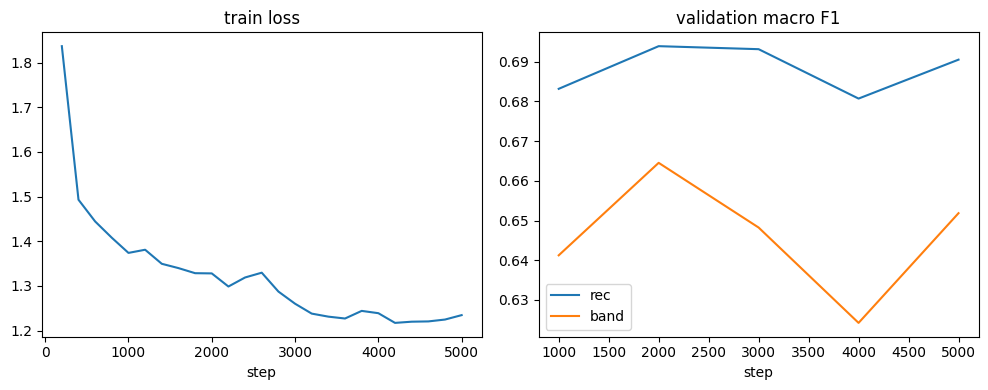

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(hist["step"], hist["train_loss"])
ax[0].set_title("train loss")
ax[0].set_xlabel("step")
ax[1].plot(hist["val_step"], hist["val_f1_rec"], label="rec")
ax[1].plot(hist["val_step"], hist["val_f1_band"], label="band")
ax[1].set_title("validation macro F1")
ax[1].set_xlabel("step")
ax[1].legend()
plt.tight_layout()
plt.savefig(OUT / "fig_transformer_curves.png", dpi=150)
plt.show()

In [7]:
res_va, _, _ = score_split(ds_va)
res_te, Pr, Pb = score_split(ds_te)
for name, r in (("rec", res_te["rec"]), ("band", res_te["band"])):
    print(f"{name} TEST macro_f1={r['macro_f1']:.4f} acc={r['accuracy']:.4f} bal_acc={r['balanced_accuracy']:.4f}",
          f"ord_err={r['ordinal_distance_error']:.4f}" if "ordinal_distance_error" in r else "")
    for c, m in r["per_class"].items():
        print(f"   {c:16s} P={m['precision']:.3f} R={m['recall']:.3f} F1={m['f1']:.3f} n={m['support']}")

for task, P, y, classes in (("recommendation", Pr, ds_te.yr, REC), ("rating_band", Pb, ds_te.yb, BAND)):
    m = y >= 0
    pr = pd.DataFrame({"id": test["id"].values[m], "y_true": [classes[i] for i in y[m]],
                       "y_pred": [classes[i] for i in P[m].argmax(1)]})
    for i, c in enumerate(classes): pr[f"p_{c}"] = P[m][:, i]
    pr.to_parquet(OUT / f"preds_transformer_{task}_test.parquet", index=False)

json.dump({"model": MODEL_NAME, "license": "apache-2.0", "max_len": MAX_LEN, "batch": BATCH,
           "epochs": EPOCHS, "lr_encoder": LR_ENCODER, "lr_head": LR_HEAD, "seed": SEED,
           "params_total": n_total, "params_trainable": n_train, "selected_step": best["step"],
           "train_rows": len(ds_tr), "val_rows": len(ds_va), "test_rows": len(ds_te),
           "val": res_va, "test": res_te, "history": hist},
          open(OUT / "transformer_metrics.json", "w"), indent=2)

rec TEST macro_f1=0.6954 acc=0.8312 bal_acc=0.7411 
   recommended      P=0.959 R=0.875 F1=0.915 n=624094
   not_recommended  P=0.652 R=0.804 F1=0.720 n=75675
   no_idea          P=0.384 R=0.543 F1=0.450 n=89054
band TEST macro_f1=0.6665 acc=0.7576 bal_acc=0.6849 ord_err=0.2621
   low              P=0.651 R=0.740 F1=0.693 n=84416
   medium           P=0.420 R=0.482 F1=0.449 n=158774
   high             P=0.884 R=0.833 F1=0.858 n=600384


In [8]:
import os
print(os.listdir("/kaggle/working"))

['__notebook__.ipynb', 'tokenizer', 'preds_transformer_rating_band_test.parquet', 'fig_transformer_curves.png', 'transformer_best.pt', 'preds_transformer_recommendation_test.parquet', 'transformer_metrics.json']
